# Wormhole Vectors (on Retrotech / Ecommerce Data)

Most hybrid search combines BM25 over keywords with kNN over dense embeddings and fuses the two result lists after the fact. Most agentic search does the same thing one level up: lexical search and semantic search are two *independent tools* that each hand back their own results.



**Wormhole vectors** instead use the documents already in your index to jump between vector spaces at query time:

> *Query in one vector space → take the top-K documents → pool their representation in a **target** space → use that pooled representation as a new query there.*

This notebook builds three vector spaces over the real RetroTech e-commerce catalog from [*AI-Powered Search*](https://aipoweredsearch.com) and traverses between them — entirely with OpenSearch primitives:

| Space | What it captures | How OpenSearch serves it | Wormhole *into* this space |
|---|---|---|---|
| **Sparse / Lexical** | what a product *says* | the inverted index (BM25 / `multi_match`) | `significant_text` aggregation over the source doc set — OpenSearch's built-in foreground-vs-background scoring is a **Semantic Knowledge Graph** traversal |
| **Dense / Semantic** | what a product *means* | `knn_vector` field `content_embedding` (HNSW) | pool the top-K docs' `content_embedding` (fetched with `_mget`) → `knn` query |
| **Behavioral** | what customers *do* with it | `knn_vector` field `behavioral_embedding` (ALS item factors) | pool the top-K docs' `behavioral_embedding` → `knn` query |

All three live on **one index**, so a single OpenSearch [`hybrid` query](https://opensearch.org/docs/latest/query-dsl/compound/hybrid/) can combine BM25 on the original query, a kNN on a *wormhole* content vector, a kNN on a *wormhole* behavioral vector and a boosted SKG term expansion — and the `normalization-processor` search pipeline fuses them server-side. That is "jumping back and forth between multiple dense and sparse vector spaces in the same query".

The last section wraps the traversals as **tools for an agent**, so an LLM can hop between spaces instead of treating "keyword search" and "vector search" as two unrelated tools.

### Prerequisites

Run inside the `ai-powered-search` Docker environment (`docker compose up opensearch`) with the RetroTech `products` and `signals` indexes loaded. Nothing else in the book's codebase is required — the notebook talks to OpenSearch over plain HTTP.

The agentic section needs an `ANTHROPIC_API_KEY` in the environment (or a `.anthropic_key` file next to this notebook); it is skipped otherwise.

In [1]:
# ── Cell 1: Imports & configuration ─────────────────────────────────────────
import os, sys, json, time, math, html, warnings
from collections import Counter, OrderedDict
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import re
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.preprocessing import normalize
import scipy.sparse as sp
warnings.filterwarnings("ignore")

SESSION = requests.Session()

# ══ OpenSearch ═════════════════════════════════════════════════════════════
def _first_reachable(urls):
    for u in urls:
        try:
            if SESSION.get(f"{u}/_cluster/health", timeout=3).ok: return u
        except Exception: pass
    return urls[0]

OPENSEARCH_URL = os.getenv("AIPS_OPENSEARCH_URL") or _first_reachable([
    f'http://{os.getenv("AIPS_OPENSEARCH_HOST", "aips-opensearch")}:'
    f'{os.getenv("AIPS_OPENSEARCH_PORT", "9200")}',
    "http://opensearch-node1:9200", "http://localhost:9200"])

PRODUCTS_INDEX  = "products"            # loaded by the book's ch04 loader
SIGNALS_INDEX   = "signals"
WORMHOLE_INDEX  = "products_wormhole"   # built here: text + both embeddings

# kNN settings for the wormhole index. Both vector fields are L2-normalized
# before indexing, so cosine similarity == inner product.
KNN_ENGINE  = "lucene"                  # "lucene" | "faiss"
KNN_SPACE   = "cosinesimil"
KNN_PARAMS  = {"ef_construction": 128, "m": 24}
KNN_EF_SEARCH = 100
BULK_BATCH  = 500

REBUILD_INDEX = os.getenv("WORMHOLE_REBUILD", "0") == "1"   # True: drop + rebuild products_wormhole

# ══ Scale ══════════════════════════════════════════════════════════════════
N_PRODUCTS      = None                  # None = whole catalog
TFIDF_MAX_FEAT  = 200_000               # in-memory sparse space (visualization only —
TFIDF_MIN_DF    = 3                     # OpenSearch's inverted index serves it in queries)
PLOT_SAMPLE     = 8_000
TSNE_SAMPLE     = 4_000
TSNE_PRE_DIMS   = 50

# ══ Embeddings / clustering ════════════════════════════════════════════════
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"   # 384-dim
EMBED_BATCH     = 128
N_CLUSTERS      = 100

# ══ Behavioral signals ═════════════════════════════════════════════════════
SIGNAL_WEIGHTS = {"purchase": 3.0, "add-to-cart": 2.0, "click": 1.0}
MIN_USER_INTERACTIONS = 2
MIN_ITEM_INTERACTIONS = 2

# ══ ALS ════════════════════════════════════════════════════════════════════
N_LATENT    = 32
ALS_ITER    = 15
ALS_REG     = 0.15
ALS_ALPHA   = 40.0
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
SPARK_DRIVER_MEMORY = os.getenv("AIPS_SPARK_DRIVER_MEMORY", "6g")

# ══ Wormholes ══════════════════════════════════════════════════════════════
TOP_K       = 5      # results shown
WORMHOLE_K  = 4      # docs pooled into a dense/behavioral wormhole vector
SKG_K       = 20     # docs used as the foreground for a sparse (SKG) wormhole
SKG_TERMS   = 12     # terms kept from a significant_text traversal
SKG_MIN_DOC_COUNT = 3        # a term must appear in ≥3 of the foreground docs
SKG_CATEGORIES    = 3        # categories kept by a two-level (category → terms) traversal
SKG_CAT_TERMS     = 6        # terms kept per category
SKG_MIN_CATEGORY_DOCS = 3    # a category needs ≥3 of the hop's docs to count as a sense
SKG_MIN_BG_COUNT  = 25       # a term must occur in ≥25 docs index-wide. This is the SKG's
                             # "min_popularity": without it, one-off brand tokens win on
                             # tiny background counts (aidata^1.00 for "ipad").
SKG_EXCLUDE = r"[0-9].*|.{1,2}|[^a-z0-9'.-]+"   # drop model numbers, 1-2 char tokens, symbols
SKG_STOPWORDS = set(ENGLISH_STOP_WORDS)             # significant_text ignores include/exclude,
                                                    # so filtering happens client-side

print(f"OpenSearch  : {OPENSEARCH_URL}")
print(f"Index       : {WORMHOLE_INDEX}  (knn engine={KNN_ENGINE}, space={KNN_SPACE})")

OpenSearch  : http://aips-opensearch:9200
Index       : products_wormhole  (knn engine=lucene, space=cosinesimil)


In [2]:
from aips import get_engine
import aips.indexer
engine = get_engine()
products_collection = aips.indexer.build_collection(engine, "products")
signals_collection = aips.indexer.build_collection(engine, "signals")

Wiping "products" collection
Creating "products" collection
Loading Products
Schema: 
root
 |-- upc: string (nullable = true)
 |-- name: string (nullable = true)
 |-- manufacturer: string (nullable = true)
 |-- short_description: string (nullable = true)
 |-- long_description: string (nullable = true)

Successfully written 48194 documents
Wiping "signals" collection
Creating "signals" collection
Loading data/retrotech/signals.csv
Schema: 
root
 |-- query_id: string (nullable = true)
 |-- user: string (nullable = true)
 |-- type: string (nullable = true)
 |-- target: string (nullable = true)
 |-- signal_time: timestamp (nullable = true)

Successfully written 2172605 documents


## 0  The OpenSearch backend — every engine call in one place

Unlike the Vespa version of this notebook, nothing here needs an application package: indexes, mappings, kNN fields and search pipelines are all created at runtime over the REST API. The interesting methods are the last four:

- **`significant_terms()`** — the sparse-space wormhole. OpenSearch's `significant_text` aggregation scores every term in a *foreground* document set against the *background* corpus. That is exactly the foreground/background relatedness scoring of a Semantic Knowledge Graph, so we get SKG traversals for free.
- **`get_vectors()`** — `_mget` the stored vectors of a doc set so they can be pooled into a dense or behavioral wormhole vector.
- **`hybrid()`** — the native `hybrid` query with an inline `normalization-processor` search pipeline: min-max normalize each sub-query's scores, then combine with weights.
- **`knn()`** — approximate nearest neighbours over either `knn_vector` field.

In [3]:
# ── Cell 2: OpenSearch backend ──────────────────────────────────────────────
class OpenSearchBackend:
    name = "opensearch"

    def __init__(self, url):
        self.url = url.rstrip("/")
        info = SESSION.get(self.url).json()
        self.version = info["version"]["number"]
        self.major, self.minor = (int(x) for x in self.version.split(".")[:2])
        self.caps = {}          # filled by probe_capabilities() once an index exists

    def probe_capabilities(self, index):
        """Ask the cluster what it can do rather than hardcoding version numbers.
        The wormhole traversals work on every version; these only decide HOW the
        results are combined and constrained.

          hybrid_filter  — a top-level `filter` on the hybrid query (rejected on
                           2.18: "Field is not supported by [hybrid] query"), so
                           the constraint has to go inside each sub-query instead.
          rrf            — the `score-ranker-processor` search pipeline (2.19+),
                           i.e. Reciprocal Rank Fusion inside the engine rather
                           than in the notebook.
          agentic        — the `agentic` query type (3.2+), OpenSearch planning
                           and running the retrieval from a natural-language ask.
        """
        probe = {"multi_match": {"query": "test", "fields": ["name"]}}
        pipe = {"phase_results_processors": [{"normalization-processor": {
                    "normalization": {"technique": "min_max"},
                    "combination": {"technique": "arithmetic_mean"}}}]}
        def runs(body):
            """Does the cluster execute this end to end?"""
            try: self.search(index, body); return True
            except RuntimeError: return False

        def query_type_exists(body):
            """Does the cluster KNOW this query type? An unsupported type fails
            with parsing_exception "unknown query [x]"; a supported one that
            needs extra setup fails later, at execution."""
            try: self.search(index, body); return True
            except RuntimeError as e: return "unknown query" not in str(e)

        self.caps["hybrid_filter"] = runs(
            {"size": 0, "query": {"hybrid": {"queries": [probe],
             "filter": {"match_all": {}}}}, "search_pipeline": pipe})
        self.caps["rrf"] = runs(
            {"size": 0, "query": {"hybrid": {"queries": [probe, probe]}},
             "search_pipeline": {"phase_results_processors": [
                 {"score-ranker-processor": {"combination": {"technique": "rrf"}}}]}})
        # The agentic query needs an ML agent bound through a search pipeline, so it
        # cannot be executed by a probe — we only ask whether the type is available.
        self.caps["agentic"] = query_type_exists(
            {"size": 0, "query": {"agentic": {"query_text": "probe"}}})
        print(f"OpenSearch {self.version} capabilities: " + ", ".join(
            f"{k}={'yes' if v else 'no'}" for k, v in self.caps.items()))
        return self.caps

    # ── low level ──────────────────────────────────────────────────────────
    def _req(self, method, path, **kw):
        r = SESSION.request(method, f"{self.url}{path}", **kw)
        if r.status_code >= 400:
            raise RuntimeError(f"OpenSearch {method} {path} failed "
                               f"({r.status_code}): {r.text[:600]}")
        return r.json() if r.text else {}

    def search(self, index, body, **params):
        return self._req("POST", f"/{index}/_search", json=body, params=params)

    def count(self, index, query=None):
        body = {"query": query} if query else {}
        return self._req("POST", f"/{index}/_count", json=body)["count"]

    def index_exists(self, index):
        return SESSION.head(f"{self.url}/{index}").status_code == 200

    def sample_fields(self, index):
        hits = self.search(index, {"size": 1})["hits"]["hits"]
        return sorted(hits[0]["_source"].keys()) if hits else []

    def scan(self, index, fields, query=None, page=5000):
        """Scroll through an index — the deep-paging primitive."""
        body = {"size": page, "_source": fields, "sort": ["_doc"],
                "query": query or {"match_all": {}}}
        data = self._req("POST", f"/{index}/_search", json=body,
                         params={"scroll": "5m"})
        sid = data["_scroll_id"]
        try:
            while True:
                hits = data["hits"]["hits"]
                if not hits: break
                for h in hits:
                    yield h["_source"] | {"_id": h["_id"]}
                data = self._req("POST", "/_search/scroll",
                                 json={"scroll": "5m", "scroll_id": sid})
                sid = data["_scroll_id"]
        finally:
            SESSION.delete(f"{self.url}/_search/scroll", json={"scroll_id": sid})

    # ── retrieval ──────────────────────────────────────────────────────────
    @staticmethod
    def _hits(data):
        return [h["_source"] | {"_id": h["_id"], "score": h.get("_score")}
                for h in data["hits"]["hits"]]

    def lexical_query(self, query, fields):
        return {"multi_match": {"query": query, "fields": fields,
                                "type": "best_fields", "operator": "or"}}

    def keyword_search(self, index, query, fields, k, return_fields=None):
        body = {"size": k, "query": self.lexical_query(query, fields)}
        if return_fields: body["_source"] = return_fields
        return self._hits(self.search(index, body))

    def knn_query(self, field, vector, k, filter=None):
        q = {"vector": [float(x) for x in vector], "k": k}
        if filter is not None: q["filter"] = filter
        return {"knn": {field: q}}

    def knn(self, index, field, vector, k, return_fields=None, filter=None):
        body = {"size": k, "query": self.knn_query(field, vector, k, filter)}
        if return_fields: body["_source"] = return_fields
        return self._hits(self.search(index, body))

    def get_vectors(self, index, ids, field):
        """Stored vectors for a doc set (the raw material of a wormhole vector)."""
        data = self._req("POST", f"/{index}/_mget", json={"ids": list(ids)},
                         params={"_source_includes": field})
        out = {}
        for d in data["docs"]:
            if d.get("found") and field in d["_source"]:
                out[d["_id"]] = np.asarray(d["_source"][field], dtype=np.float32)
        return out

    def significant_terms(self, index, ids, fields, size=SKG_TERMS,
                          heuristic=None, min_doc_count=SKG_MIN_DOC_COUNT,
                          exclude=SKG_EXCLUDE, normalize_scores=True):
        """SKG-style traversal: which terms are over-represented in this doc
        set (foreground) relative to the whole index (background)?

        significant_text re-analyzes _source, so it works on plain text fields
        with no fielddata. `heuristic` is one of the aggregation's scoring
        options: None (JLH, the default), "mutual_information", "chi_square",
        "gnd", "percentage". Stopwords and tokens matching `exclude` are
        filtered client-side (the aggregation over-fetches to compensate).
        """
        aggs = {}
        for f in fields:
            spec = {"field": f, "size": size * 4, "min_doc_count": min_doc_count,
                    "filter_duplicate_text": True}
            if heuristic: spec[heuristic] = {}
            aggs[f] = {"significant_text": spec}
        drop = lambda t: t in SKG_STOPWORDS or (exclude and re.fullmatch(exclude, t))
        body = {"size": 0, "query": {"ids": {"values": list(ids)}}, "aggs": aggs}
        data = self.search(index, body)
        terms = {}
        for f in fields:
            for b in data["aggregations"][f]["buckets"]:
                t = b["key"]
                if drop(t): continue
                if t not in terms or b["score"] > terms[t]["score"]:
                    terms[t] = {"term": t, "score": b["score"], "field": f,
                                "fg": b["doc_count"], "bg": b["bg_count"]}
        top = sorted(terms.values(), key=lambda x: -x["score"])[:size]
        if normalize_scores and top:                     # → relatedness-style weights in (0, 1]
            mx = top[0]["score"]
            for t in top: t["score"] = round(t["score"] / mx, 4)
        return top

    def significant_terms_two_level(self, index, ids, category_field, text_fields,
                                    n_categories=SKG_CATEGORIES, n_terms=SKG_CAT_TERMS,
                                    min_doc_count=2, min_bg_count=SKG_MIN_BG_COUNT,
                                    min_category_docs=SKG_MIN_CATEGORY_DOCS,
                                    heuristic=None, normalize_scores=True):
        """A TWO-LEVEL SKG traversal in ONE request: which CATEGORIES are
        over-represented in this document set, and — inside each one — which TERMS?

        Nesting significant_text inside significant_terms gives similar semantics
        to an SKG nested traversal uses: each category bucket becomes the
        foreground for the level below it, while the background stays the whole
        index. So the terms are the ones distinctive to *these documents, in this
        category* — which is what makes the output contextually disambiguated
        rather than a single flat bag of terms.
        """
        text_aggs = {}
        for f in text_fields:
            spec = {"field": f, "size": n_terms * 4, "min_doc_count": min_doc_count,
                    "filter_duplicate_text": True}
            if heuristic: spec[heuristic] = {}
            text_aggs[f"terms__{f}"] = {"significant_text": spec}
        cat_spec = {"field": category_field, "size": n_categories,
                    "min_doc_count": min_doc_count}
        if heuristic: cat_spec[heuristic] = {}
        body = {"size": 0, "query": {"ids": {"values": list(ids)}},
                "aggs": {"category": {"significant_terms": cat_spec, "aggs": text_aggs}}}
        agg = self.search(index, body)["aggregations"]["category"]

        drop = lambda t: t in SKG_STOPWORDS or re.fullmatch(SKG_EXCLUDE, t)
        senses = []
        for cat in agg["buckets"]:
            if cat["doc_count"] < min_category_docs: continue   # too small to be a real sense
            terms = {}
            for f in text_fields:
                for b in cat[f"terms__{f}"]["buckets"]:
                    t = b["key"]
                    if drop(t) or b["bg_count"] < min_bg_count: continue
                    if t not in terms or b["score"] > terms[t]["score"]:
                        terms[t] = {"term": t, "score": b["score"], "field": f,
                                    "fg": b["doc_count"], "bg": b["bg_count"]}
            top = sorted(terms.values(), key=lambda x: -x["score"])[:n_terms]
            if not top: continue
            if normalize_scores:
                mx = top[0]["score"]
                for t in top: t["score"] = round(t["score"] / mx, 4)
            senses.append({"category": cat["key"], "docs": cat["doc_count"],
                           "category_score": round(cat["score"], 2),
                           "share": round(cat["doc_count"] / max(1, agg["doc_count"]), 3),
                           "terms": top})
        return senses

    def terms_query(self, weighted_terms, field):
        """A sparse wormhole *query*: boosted should-clauses, one per term."""
        return {"bool": {"should": [
            {"match": {field: {"query": t["term"], "boost": round(float(t["score"]), 4)}}}
            for t in weighted_terms]}}

    def constrain_hybrid(self, body, field, value):
        """Constrain a whole hybrid query to one category, the cheap way when the
        cluster supports it."""
        body = json.loads(json.dumps(body))
        body["query"]["hybrid"]["filter"] = {"term": {field: value}}
        return body

    def constrain(self, query, field, value):
        """Restrict a sub-query to one category. OpenSearch 2.18's `hybrid` query
        takes no top-level filter, so the constraint goes INSIDE each sub-query:
        natively for knn (applied during the HNSW traversal), and as a bool filter
        for everything else. Filtering per sub-query — rather than post_filter —
        keeps each sub-query's own top-k pool inside the category."""
        filt = {"term": {field: value}}
        if "knn" in query:
            q = json.loads(json.dumps(query))            # don't mutate the caller's dict
            for spec in q["knn"].values(): spec["filter"] = filt
            return q
        return {"bool": {"must": [query], "filter": filt}}

    def hybrid(self, index, queries, k, weights=None, normalization="min_max",
               combination="arithmetic_mean", return_fields=None, pipeline=None,
               filter=None, rrf=False):
        """OpenSearch's native hybrid query. Sub-query scores are normalized and
        combined by a search pipeline; an inline (temporary) pipeline keeps the
        notebook self-contained, `pipeline=` uses a stored one instead."""
        body = {"size": k, "query": {"hybrid": {"queries": queries}}}
        if return_fields: body["_source"] = return_fields
        params = {}
        if pipeline:
            params["search_pipeline"] = pipeline
        elif rrf and self.caps.get("rrf"):
            # Reciprocal Rank Fusion in the engine (2.19+) — no score normalization
            body["search_pipeline"] = {"phase_results_processors": [
                {"score-ranker-processor": {"combination": {"technique": "rrf"}}}]}
        else:
            comb = {"technique": combination}
            if weights: comb["parameters"] = {"weights": [float(w) for w in weights]}
            body["search_pipeline"] = {"phase_results_processors": [
                {"normalization-processor": {
                    "normalization": {"technique": normalization},
                    "combination": comb}}]}
        if filter is not None:
            body = self.constrain_hybrid(body, *filter)
        return self._hits(self.search(index, body, **params))

    # ── index management ───────────────────────────────────────────────────
    def wormhole_mapping(self, content_dims, behavioral_dims):
        def knn_field(dims):
            return {"type": "knn_vector", "dimension": dims,
                    "method": {"name": "hnsw", "space_type": KNN_SPACE,
                               "engine": KNN_ENGINE, "parameters": KNN_PARAMS}}
        text = lambda: {"type": "text", "copy_to": "text"}
        return {
            "settings": {"index": {"knn": True,
                                   "knn.algo_param.ef_search": KNN_EF_SEARCH,
                                   "number_of_shards": 1, "number_of_replicas": 0}},
            "mappings": {"properties": {
                "upc": {"type": "keyword"},
                "name": text(), "manufacturer": text(),
                "short_description": text(), "long_description": text(),
                "text": {"type": "text"},
                "cluster_id": {"type": "integer"},
                "cluster_label": {"type": "keyword"},
                "content_embedding": knn_field(content_dims),
                "behavioral_embedding": knn_field(behavioral_dims)}}}

    def ensure_wormhole_index(self, index, content_dims, behavioral_dims,
                              rebuild=False):
        if self.index_exists(index):
            if not rebuild:
                print(f"Index '{index}' exists — reusing it")
                return False
            self._req("DELETE", f"/{index}")
            print(f"Dropped '{index}'")
        self._req("PUT", f"/{index}", json=self.wormhole_mapping(content_dims,
                                                                 behavioral_dims))
        print(f"Created '{index}' with knn_vector fields "
              f"content_embedding[{content_dims}] and behavioral_embedding[{behavioral_dims}]")
        return True

    def bulk(self, index, docs, action="index", batch=BULK_BATCH):
        """docs: iterable of dicts with an 'id' key. action: index | update."""
        docs = list(docs)
        for i in range(0, len(docs), batch):
            lines = []
            for d in docs[i:i+batch]:
                body = {k: v for k, v in d.items() if k != "id"}
                lines.append(json.dumps({action: {"_index": index, "_id": d["id"]}}))
                lines.append(json.dumps({"doc": body} if action == "update" else body))
            r = SESSION.post(f"{self.url}/_bulk", data="\n".join(lines) + "\n",
                             headers={"Content-Type": "application/x-ndjson"})
            resp = r.json()
            if r.status_code >= 400 or resp.get("errors"):
                bad = [it for it in resp.get("items", [])
                       if list(it.values())[0].get("error")][:2]
                raise RuntimeError(f"bulk failed: {r.status_code} {bad or r.text[:400]}")
            if i and i % 10000 == 0: print(f"   {i:,} / {len(docs):,} ...")
        self._req("POST", f"/{index}/_refresh")
        print(f"{'updated' if action == 'update' else 'indexed'} {len(docs):,} docs into '{index}'")


backend = OpenSearchBackend(OPENSEARCH_URL)
print(f"OpenSearch {backend.version}")
print(f"  {PRODUCTS_INDEX:<10}: {backend.count(PRODUCTS_INDEX):,} docs")
print(f"  {SIGNALS_INDEX:<10}: {backend.count(SIGNALS_INDEX):,} docs")

OpenSearch 3.8.0
  products  : 46,156 docs
  signals   : 2,172,605 docs


## 1  Load the catalog and the behavioral signals

Both come straight out of OpenSearch with the scroll API. The signals index has 2M+ rows; we keep only the product-level ones (`purchase`, `add-to-cart`, `click`) — `query` signals target a query string, not a product.

In [4]:
# ── Cell 3: Catalog ──────────────────────────────────────────────────────────
def first(v):
    if isinstance(v, list): return v[0] if v else ""
    return v if v is not None else ""

t0 = time.time()
TEXT_FIELDS = ["name", "manufacturer", "short_description", "long_description"]
records, seen = [], set()
for d in backend.scan(PRODUCTS_INDEX, ["upc"] + TEXT_FIELDS):
    upc = str(first(d.get("upc"))).strip()
    if not upc or upc in seen: continue
    raw_name = str(first(d.get("name"))).strip()
    # the catalog carries HTML entities (Apple&#xAE;) — unescape for display/embedding
    parts = {f: html.unescape(str(first(d.get(f))).strip()) for f in TEXT_FIELDS}
    text = " ".join(p for p in parts.values() if p)
    if len(text) < 3: continue
    seen.add(upc)
    records.append({"upc": upc, **parts, "raw_name": raw_name, "text": text})
df = pd.DataFrame(records); del records, seen
if N_PRODUCTS: df = df.head(N_PRODUCTS)
print(f"Catalog: {len(df):,} products in {time.time()-t0:.1f}s")
df.head(3)[["upc", "name", "manufacturer"]]

Catalog: 46,156 products in 1.2s


,upc,name,manufacturer
0,93279831017,Newcastle - 700W 7.1-Ch. A/V Home Theater Rece...,Newcastle
1,93279830232,Sherwood - Bluetooth Audio Dongle for Select S...,Sherwood
2,14633098495,The Orange Box Platinum Hits - Xbox 360,Electronic Arts


In [5]:
# ── Cell 4: Signals ──────────────────────────────────────────────────────────
t0 = time.time()
corpus_upcs = set(df["upc"])
# The book's products loader strips leading zeros from UPCs (096009010836 →
# 96009010836) but the signals CSV keeps them — about 35% of product-level
# signals — so normalize before joining. (Also accept a product *name* as the
# target, which is what an older OpenSearch UBI round-trip produced.)
name_to_upc = {}
for u, n in zip(df["upc"], df["raw_name"]):
    name_to_upc.setdefault(n, u)
def resolve_target(t):
    if t in corpus_upcs: return t
    stripped = t.lstrip("0")
    if stripped in corpus_upcs: return stripped
    return name_to_upc.get(t)
rows, n_seen = [], 0
for d in backend.scan(SIGNALS_INDEX, ["user", "type", "target"],
                      query={"bool": {"must_not": {"match": {"type": "query"}}}},
                      page=10000):
    n_seen += 1
    tgt = resolve_target(str(first(d.get("target"))))
    typ = str(first(d.get("type")))
    if tgt and typ in SIGNAL_WEIGHTS:
        rows.append((str(first(d.get("user"))), tgt, typ))
    if n_seen % 500000 == 0: print(f"   scanned {n_seen:,} signals ...")
signals_df = pd.DataFrame(rows, columns=["user", "product", "type"]); del rows
signals_df["w"] = signals_df["type"].map(SIGNAL_WEIGHTS).astype("float32")
print(f"Signals: {len(signals_df):,} product-level rows ({n_seen:,} scanned) "
      f"in {time.time()-t0:.0f}s")
print(signals_df["type"].value_counts().to_string())

purchase_counts = signals_df[signals_df["type"] == "purchase"]["product"].value_counts()
df["purchases"] = df["upc"].map(purchase_counts).fillna(0).astype(int)
df = df.sort_values("purchases", ascending=False).reset_index(drop=True)
print(f"\nProducts with ≥1 purchase: {(df['purchases'] > 0).sum():,} / {len(df):,}")

   scanned 500,000 signals ...
   scanned 1,000,000 signals ...
Signals: 1,447,146 product-level rows (1,447,146 scanned) in 24s
type
click          647684
add-to-cart    404454
purchase       395008

Products with ≥1 purchase: 21,921 / 46,156


## 2  Space 2 — dense / semantic: embed the catalog and build `products_wormhole`

Embed every product, k-means the embeddings into 100 clusters (labelled from their members' most distinctive name terms — handy for reading results), and index **text + `content_embedding`** into one OpenSearch index with a `knn_vector` mapping. The behavioral vectors are added to the same documents later, once ALS has produced them.

The embedding pass is the longest step (a few minutes on CPU). It runs once; later runs load the vectors back out of OpenSearch.

In [6]:
# ── Cell 5: Embeddings + clusters → OpenSearch ──────────────────────────────
from sentence_transformers import SentenceTransformer
from sklearn.cluster import MiniBatchKMeans

st_model = SentenceTransformer(EMBEDDING_MODEL)
EMB_DIMS = st_model.get_sentence_embedding_dimension()

def index_is_populated():
    try:
        if not backend.index_exists(WORMHOLE_INDEX): return False
        props = backend._req("GET", f"/{WORMHOLE_INDEX}/_mapping")[WORMHOLE_INDEX] \
                       ["mappings"]["properties"]
        return "content_embedding" in props and backend.count(WORMHOLE_INDEX) > 0
    except Exception:
        return False

if index_is_populated() and not REBUILD_INDEX:
    print(f"'{WORMHOLE_INDEX}' is populated — loading embeddings back from OpenSearch")
    vecs, upcs, labels, cids = [], [], {}, {}
    for d in backend.scan(WORMHOLE_INDEX, ["upc", "content_embedding",
                                           "cluster_label", "cluster_id"], page=2000):
        upcs.append(d["upc"]); vecs.append(np.asarray(d["content_embedding"], dtype=np.float32))
        labels[d["upc"]] = d.get("cluster_label", "(unclustered)")
        cids[d["upc"]] = int(d.get("cluster_id", -1))
    X_all = np.vstack(vecs); del vecs
    row_of = {u: i for i, u in enumerate(upcs)}
    have = df["upc"].map(lambda u: u in row_of)
    if (~have).any():
        print(f"   dropping {(~have).sum():,} products with no stored embedding")
        df = df[have].reset_index(drop=True)
    dense_matrix = X_all[[row_of[u] for u in df["upc"]]]; del X_all
    df["category"]   = df["upc"].map(labels).fillna("(unclustered)")
    df["cluster_id"] = df["upc"].map(cids).fillna(-1).astype(int)
    INDEX_BUILT = False
else:
    t0 = time.time()
    print(f"Embedding {len(df):,} products with {EMBEDDING_MODEL} ...")
    dense_matrix = st_model.encode(df["text"].str.slice(0, 512).tolist(),
                                   batch_size=EMBED_BATCH, show_progress_bar=False,
                                   normalize_embeddings=True).astype(np.float32)
    print(f"   embedded in {time.time()-t0:.0f}s → {dense_matrix.shape}")

    k = min(N_CLUSTERS, max(2, len(df) // 5))
    km = MiniBatchKMeans(n_clusters=k, random_state=RANDOM_SEED, batch_size=4096,
                         n_init=5).fit(dense_matrix)
    cluster_text = pd.Series(df["name"].values).groupby(km.labels_).apply(" ".join)
    lab_tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                                max_features=50_000)
    M = lab_tfidf.fit_transform(cluster_text.values)
    terms = lab_tfidf.get_feature_names_out()
    cluster_labels = {int(cid): " / ".join(
                          terms[t] for t in np.asarray(M[row].todense()).ravel()
                                                 .argsort()[::-1][:3])
                      for row, cid in enumerate(cluster_text.index)}
    df["cluster_id"] = km.labels_.astype(int)
    df["category"]   = df["cluster_id"].map(cluster_labels)
    print(f"   k-means: {k} clusters, e.g. " +
          "; ".join(cluster_labels[c] for c in list(cluster_labels)[:4]))

    backend.ensure_wormhole_index(WORMHOLE_INDEX, EMB_DIMS, N_LATENT, rebuild=True)
    docs = ({"id": r.upc, "upc": r.upc, "name": r.name, "manufacturer": r.manufacturer,
             "short_description": r.short_description,
             "long_description": r.long_description,
             "cluster_id": int(r.cluster_id), "cluster_label": r.category,
             "content_embedding": [round(float(x), 5) for x in vec]}
            for r, vec in zip(df.itertuples(), dense_matrix))
    backend.bulk(WORMHOLE_INDEX, docs)
    INDEX_BUILT = True
    print(f"Total build time: {time.time()-t0:.0f}s")

backend.probe_capabilities(WORMHOLE_INDEX)

dense_matrix = normalize(dense_matrix, norm="l2")
print(f"\nDense space: {dense_matrix.shape[0]:,} × {dense_matrix.shape[1]} "
      f"| {df['category'].nunique()} cluster labels")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding 46,156 products with sentence-transformers/all-MiniLM-L6-v2 ...
   embedded in 283s → (46156, 384)
   k-means: 100 clusters, e.g. audioquest / cable / hdmi; dvd / season / csi; subtitle / subtitle dvd / dvd; mouse / wireless / keyboard
Created 'products_wormhole' with knn_vector fields content_embedding[384] and behavioral_embedding[32]
   10,000 / 46,156 ...
   20,000 / 46,156 ...
   30,000 / 46,156 ...
   40,000 / 46,156 ...
indexed 46,156 docs into 'products_wormhole'
Total build time: 320s
OpenSearch 3.8.0 capabilities: hybrid_filter=yes, rrf=yes, agentic=yes

Dense space: 46,156 × 384 | 96 cluster labels


## 3  Space 3 — behavioral: ALS over the purchase / cart / click signals

Same recipe as `ch09/1.personalization.ipynb`: implicit-feedback ALS in Spark, weighted by signal type. Collaborative filtering only learns from *co-occurrence*, so users and items with a single interaction are dropped first.

In [7]:
# ── Cell 6: Preferences ─────────────────────────────────────────────────────
prefs_pd = (signals_df.groupby(["user", "product"])["w"].sum()
            .rename("preference").reset_index())
raw_rows = len(prefs_pd)
for _ in range(3):
    prefs_pd = prefs_pd[prefs_pd.groupby("user")["product"].transform("size") >= MIN_USER_INTERACTIONS]
    prefs_pd = prefs_pd[prefs_pd.groupby("product")["user"].transform("size") >= MIN_ITEM_INTERACTIONS]
prefs_pd = prefs_pd.reset_index(drop=True)
print(f"Interaction rows : {raw_rows:,} → {len(prefs_pd):,} after the interaction floor")
print(f"Distinct users   : {prefs_pd['user'].nunique():,}")
print(f"Distinct products: {prefs_pd['product'].nunique():,}")
print(f"Interactions/user: {len(prefs_pd)/max(1, prefs_pd['user'].nunique()):.2f}")

Interaction rows : 647,441 → 137,040 after the interaction floor
Distinct users   : 43,513
Distinct products: 12,780
Interactions/user: 3.15


In [8]:
# ── Cell 7: Spark ALS ───────────────────────────────────────────────────────
import glob
SPARK_HOME = os.getenv("SPARK_HOME", "/usr/local/spark")   # make pyspark importable outside the AIPS helpers
for p in [f"{SPARK_HOME}/python"] + glob.glob(f"{SPARK_HOME}/python/lib/py4j-*-src.zip"):
    if os.path.exists(p) and p not in sys.path: sys.path.insert(0, p)
from pyspark.sql import SparkSession
from pyspark.sql.types import StructType, StructField, IntegerType, FloatType
from pyspark.ml.recommendation import ALS

if not hasattr(pd.DataFrame, "iteritems"):        # pandas 2 ↔ PySpark 3.3 shim
    pd.DataFrame.iteritems = pd.DataFrame.items
    pd.Series.iteritems = pd.Series.items

active = SparkSession.getActiveSession()
if active is not None: active.stop()
spark = (SparkSession.builder.appName("wormhole-vectors-als").master("local[*]")
         .config("spark.driver.memory", SPARK_DRIVER_MEMORY)
         .config("spark.driver.maxResultSize", "2g")
         .config("spark.sql.shuffle.partitions", "32")
         .config("spark.default.parallelism", "32")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
spark.sparkContext.setCheckpointDir("/tmp/spark-checkpoints")

user_codes = pd.Categorical(prefs_pd["user"]); prod_codes = pd.Categorical(prefs_pd["product"])
idx_to_user = list(user_codes.categories); idx_to_upc = list(prod_codes.categories)
schema = StructType([StructField("user_idx", IntegerType(), False),
                     StructField("product_idx", IntegerType(), False),
                     StructField("preference", FloatType(), False)])
rows = list(zip(user_codes.codes.astype("int32").tolist(),
                prod_codes.codes.astype("int32").tolist(),
                prefs_pd["preference"].astype("float32").tolist()))
n_part = max(32, len(rows) // 100_000)
indexed = spark.createDataFrame(rows, schema=schema).repartition(n_part).cache()
del rows

t0 = time.time()
model = ALS(rank=N_LATENT, maxIter=ALS_ITER, regParam=ALS_REG, alpha=ALS_ALPHA,
            implicitPrefs=True, seed=RANDOM_SEED, userCol="user_idx",
            itemCol="product_idx", ratingCol="preference",
            numUserBlocks=n_part, numItemBlocks=n_part, checkpointInterval=3,
            intermediateStorageLevel="MEMORY_AND_DISK",
            finalStorageLevel="MEMORY_AND_DISK", coldStartStrategy="drop").fit(indexed)
print(f"ALS trained in {time.time()-t0:.0f}s")

def collect_factors(factor_df, labels):
    rows = factor_df.collect()
    M = np.zeros((len(rows), N_LATENT), dtype=np.float32); index = {}
    for i, r in enumerate(rows):
        M[i] = r["features"]; index[labels[r["id"]]] = i
    return M, index

item_F, item_index = collect_factors(model.itemFactors, idx_to_upc)
user_F, user_index = collect_factors(model.userFactors, idx_to_user)
indexed.unpersist()
print(f"Item factors: {item_F.shape} | User factors: {user_F.shape}  ← user-feature matrix")

ALS trained in 11s
Item factors: (12780, 32) | User factors: (43513, 32)  ← user-feature matrix


### Cold-start products: a wormhole solves its own problem

Most of the catalog has no signals, so ALS gives those products no behavioral vector. Rather than dropping them, impute one: find each cold product's nearest neighbours in the **content** space among products that *do* have factors, and pool their behavioral vectors. That imputation is itself a content→behavioral wormhole, applied per document instead of per query.

We also build an in-memory TF-IDF matrix here — **only for the visualizations**. At query time the sparse space is OpenSearch's inverted index.

In [9]:
# ── Cell 8: Align spaces, impute cold-start, TF-IDF for viz, persist ────────
t0 = time.time()
has_factor = df["upc"].map(lambda u: u in item_index).values
print(f"Products with an ALS factor: {has_factor.sum():,} / {len(df):,}")

V_latent = np.zeros((len(df), N_LATENT), dtype=np.float32)
warm_rows = np.where(has_factor)[0]
V_latent[warm_rows] = item_F[[item_index[u] for u in df["upc"].iloc[warm_rows]]]
cold_rows = np.where(~has_factor)[0]
if len(cold_rows):
    print(f"Imputing {len(cold_rows):,} cold-start behavioral vectors via a "
          f"content→behavioral wormhole (k=10) ...")
    warm_dense, warm_beh = dense_matrix[warm_rows], V_latent[warm_rows]
    for s in range(0, len(cold_rows), 512):
        block = cold_rows[s:s+512]
        sims = dense_matrix[block] @ warm_dense.T
        nn = np.argpartition(-sims, 10, axis=1)[:, :10]
        for r, (row, cols) in enumerate(zip(block, nn)):
            w = np.clip(sims[r, cols], 0, None)
            V_latent[row] = (warm_beh[cols] * w[:, None]).sum(0)
    del warm_dense, warm_beh
V_latent = normalize(V_latent, norm="l2")

tfidf = TfidfVectorizer(min_df=TFIDF_MIN_DF, max_features=TFIDF_MAX_FEAT,
                        stop_words="english", sublinear_tf=True, dtype=np.float32)
sparse_matrix = tfidf.fit_transform(df["text"])

# Persist behavioral_embedding onto the same OpenSearch documents
backend.bulk(WORMHOLE_INDEX,
             ({"id": u, "behavioral_embedding": [round(float(x), 5) for x in v]}
              for u, v in zip(df["upc"], V_latent)), action="update")

row_of_upc = {u: i for i, u in enumerate(df["upc"])}
print(f"\nAligned corpus: {len(df):,} products")
print(f"  Sparse     : {sparse_matrix.shape} nnz={sparse_matrix.nnz:,}  (in-memory, viz only)")
print(f"  Dense      : {dense_matrix.shape}  (OpenSearch knn_vector content_embedding)")
print(f"  Behavioral : {V_latent.shape}  (OpenSearch knn_vector behavioral_embedding)")
print(f"Elapsed: {time.time()-t0:.0f}s")

Products with an ALS factor: 12,780 / 46,156
Imputing 33,376 cold-start behavioral vectors via a content→behavioral wormhole (k=10) ...
   10,000 / 46,156 ...
   20,000 / 46,156 ...
   30,000 / 46,156 ...
   40,000 / 46,156 ...
updated 46,156 docs into 'products_wormhole'

Aligned corpus: 46,156 products
  Sparse     : (46156, 18840) nnz=984,662  (in-memory, viz only)
  Dense      : (46156, 384)  (OpenSearch knn_vector content_embedding)
  Behavioral : (46156, 32)  (OpenSearch knn_vector behavioral_embedding)
Elapsed: 28s


In [10]:
# ── Cell 9: Is the behavioral space real? Co-interaction lift test ──────────
# Do products the same user interacted with sit closer together than random
# pairs? Lift ≈ 0 would mean ALS learned nothing.
rng = np.random.default_rng(RANDOM_SEED)
counts = prefs_pd.groupby("user").size()
multi = counts[(counts >= 2) & (counts <= 50)].index
su = rng.choice(multi, size=min(5000, len(multi)), replace=False)
pairs = []
for _, g in prefs_pd[prefs_pd["user"].isin(set(su))].groupby("user")["product"]:
    rows_ = [row_of_upc[p] for p in g if p in row_of_upc]
    if len(rows_) >= 2:
        a, b = rng.choice(rows_, size=2, replace=False); pairs.append((int(a), int(b)))
A = np.array([p[0] for p in pairs]); B = np.array([p[1] for p in pairs])
R1 = rng.integers(0, len(df), len(pairs)); R2 = rng.integers(0, len(df), len(pairs))
for space, M in [("behavioral", V_latent), ("dense (control)", dense_matrix)]:
    co, rnd = float((M[A]*M[B]).sum(1).mean()), float((M[R1]*M[R2]).sum(1).mean())
    print(f"  {space:<18} co-interacted {co:+.4f} | random {rnd:+.4f} | lift {co-rnd:+.4f}")
print(f"  ({len(pairs):,} pairs)")

  behavioral         co-interacted +0.4154 | random +0.1050 | lift +0.3103
  dense (control)    co-interacted +0.3375 | random +0.1508 | lift +0.1866
  (5,000 pairs)


## 4  Searching each space — all served by OpenSearch

From here on the notebook holds no search index of its own. Lexical search is a `multi_match` over the text fields, and the dense and behavioral spaces are `knn` queries against the two `knn_vector` fields on the same documents.

In [11]:
# ── Cell 10: Search functions ───────────────────────────────────────────────
QF = ["name^3", "manufacturer^2", "short_description", "long_description"]
RETURN_FIELDS = ["upc", "name", "cluster_label"]

def embed_query(text):
    return normalize(st_model.encode([text]), norm="l2")[0].astype(np.float32)

def lexical_search(query, k=TOP_K):
    return backend.keyword_search(WORMHOLE_INDEX, query, QF, k, RETURN_FIELDS)

def dense_search(query, k=TOP_K):
    return backend.knn(WORMHOLE_INDEX, "content_embedding", embed_query(query), k, RETURN_FIELDS)

def vector_search(space, vec, k=TOP_K):
    field = {"dense": "content_embedding", "behavioral": "behavioral_embedding"}[space]
    return backend.knn(WORMHOLE_INDEX, field, vec, k, RETURN_FIELDS)

def show(hits, source_ids=None, max_name=58):
    for h in hits:
        flag = " ← NEW" if source_ids is not None and h["_id"] not in source_ids else ""
        print(f"   [{h['score']:.4f}] [{h.get('cluster_label','')[:26]}] "
              f"{h['name'][:max_name]}{flag}")

print('Lexical (BM25): "bluetooth headphones noise"'); show(lexical_search("bluetooth headphones noise"))
print('\nDense (kNN): "portable speaker for outdoor music"'); show(dense_search("portable speaker for outdoor music"))
print('\nBehavioral (kNN) seed:', df["name"].iloc[0][:50])
show(vector_search("behavioral", V_latent[0], 6))

Lexical (BM25): "bluetooth headphones noise"
   [19.5499] [headphones / earbud / ear] Panasonic - Noise-Canceling Headphones
   [18.3223] [headphones / earbud / ear] Sony - Sony Noise-Canceling Headphones
   [18.3223] [headphones / earbud / ear] Sennheiser - Active Noise-Canceling Headphones
   [18.3223] [headphones / earbud / ear] Sony - Digital Noise-Canceling Headphones
   [18.3223] [headphones / earbud / ear] Panasonic - Noise-Canceling Monitor Headphones

Dense (kNN): "portable speaker for outdoor music"
   [0.7982] [subwoofer / speakers / con] SpeakerCraft - OG 3" Outdoor Speaker (Each) - Bronze
   [0.7943] [subwoofer / speakers / con] Polk Audio - Atrium Sat30 Indoor/Outdoor Satellite Speaker
   [0.7941] [subwoofer / speakers / con] Bose® - 151® SE Environmental Speakers (Pair) - White
   [0.7919] [subwoofer / speakers / con] SpeakerCraft - Ruckus 8 One 2-Way Outdoor Speaker (Each) -
   [0.7896] [subwoofer / speakers / con] Boston Acoustics - Soundware 4-1/2" 2-Way Indoor/Outdoo

## 5  Wormhole vectors

Two ways to build a wormhole from a document set, depending on the target space:

1. **Into an embedding space (dense or behavioral)** — `_mget` the stored vectors of the top-K source documents and pool them (weighted by source score) into one unit vector. Then `knn`.
2. **Into the sparse / lexical space** — a `significant_text` aggregation over the top-K source documents. OpenSearch scores each term by how over-represented it is in that foreground set versus the whole index: the same foreground/background relatedness a Semantic Knowledge Graph uses. The result is a weighted term vector — a contextual sparse query — which becomes a boosted `bool.should`.

Either way, the wormhole vector is built from **the documents your engine already holds**, not from a model that has to be trained for the pair of spaces.

In [12]:
# ── Cell 11: Wormhole vector construction ───────────────────────────────────
SPACE_FIELD = {"dense": "content_embedding", "behavioral": "behavioral_embedding"}
SPACE_LABELS = {"sparse": "Sparse / Lexical", "dense": "Dense / Semantic",
                "behavioral": "Behavioral (ALS)"}

def source_search(query, space, k):
    return {"sparse": lexical_search, "dense": dense_search}[space](query, k)

def pooled_wormhole_vector(hits, target_space, weighted=True):
    """Dense/behavioral wormhole: score-weighted mean of the stored vectors."""
    vecs = backend.get_vectors(WORMHOLE_INDEX, [h["_id"] for h in hits], SPACE_FIELD[target_space])
    ids = [h["_id"] for h in hits if h["_id"] in vecs]
    w = np.array([h["score"] if weighted else 1.0 for h in hits if h["_id"] in vecs], dtype=np.float32)
    w = np.clip(w, 1e-6, None); w /= w.sum()
    pooled = (np.vstack([vecs[i] for i in ids]) * w[:, None]).sum(0)
    return pooled / (np.linalg.norm(pooled) + 1e-12)

def skg_wormhole_terms(hits, size=SKG_TERMS, fields=("name", "short_description"),
                       heuristic=None, exclude=SKG_EXCLUDE):
    """Sparse wormhole: significant_text over the source doc set."""
    return backend.significant_terms(WORMHOLE_INDEX, [h["_id"] for h in hits],
                                     list(fields), size=size, heuristic=heuristic,
                                     exclude=exclude)

def skg_wormhole_senses(hits, n_categories=SKG_CATEGORIES, n_terms=SKG_CAT_TERMS,
                        category_field="cluster_label", fields=("name", "short_description")):
    """Two-level sparse wormhole: the category first, then the terms inside it."""
    return backend.significant_terms_two_level(
        WORMHOLE_INDEX, [h["_id"] for h in hits], category_field, list(fields),
        n_categories=n_categories, n_terms=n_terms)

def fmt_sense(sense, indent="   "):
    """The {category, sparse_vector} shape the Solr / Vespa SKG traversals emit."""
    return (f'{indent}{{"category": "{sense["category"]}",'
            f'   ({sense["docs"]} docs, {sense["share"]*100:.0f}% of the hop)\n'
            f'{indent} "sparse_vector": "{fmt_terms(sense["terms"])}"}}')

def fmt_terms(terms):
    return "  ".join(f"{t['term']}^{t['score']:.2f}" for t in terms)

def search_with_wormhole(target_space, wormhole, k=TOP_K):
    """wormhole is a vector (dense/behavioral) or a term list (sparse)."""
    if target_space == "sparse":
        body = {"size": k, "_source": RETURN_FIELDS,
                "query": backend.terms_query(wormhole, "text")}
        return backend._hits(backend.search(WORMHOLE_INDEX, body))
    return vector_search(target_space, wormhole, k)

def wormhole_traverse(query, source_space="sparse", target_space="behavioral",
                      wormhole_k=None, top_k=TOP_K, verbose=True):
    """source_space query → wormhole vector → target_space results"""
    k = wormhole_k or (SKG_K if target_space == "sparse" else WORMHOLE_K)
    src = source_search(query, source_space, k)
    src_ids = {h["_id"] for h in src}
    if verbose:
        print(f'── Step 1: {SPACE_LABELS[source_space]} query: "{query}"  (top {k})')
        show(src[:TOP_K])
    if target_space == "sparse":
        wormhole = skg_wormhole_terms(src)
        if verbose: print(f"\n── Step 2-3: SKG wormhole (significant_text over {k} docs):\n   {fmt_terms(wormhole)}")
    else:
        wormhole = pooled_wormhole_vector(src, target_space)
        if verbose: print(f"\n── Step 2-3: pooled {SPACE_LABELS[target_space]} wormhole vector (dim={len(wormhole)})")
    tgt = search_with_wormhole(target_space, wormhole, top_k)
    if verbose:
        print(f"\n── Step 4: {SPACE_LABELS[target_space]} results via the wormhole")
        show(tgt, source_ids=src_ids)
    return src, wormhole, tgt

print("=" * 72); print("Sparse → Behavioral: what do people who search for this actually buy?"); print("=" * 72)
_ = wormhole_traverse("digital camera", "sparse", "behavioral")

print("\n" + "=" * 72); print("Dense → Sparse: what keywords describe what this query MEANS?"); print("=" * 72)
_ = wormhole_traverse("portable speaker for outdoor music", "dense", "sparse")

Sparse → Behavioral: what do people who search for this actually buy?
── Step 1: Sparse / Lexical query: "digital camera"  (top 4)
   [12.3751] [lowepro / case / black] Nikon - Digital SLR Camera Bag
   [12.3751] [megapixel / megapixel digi] Olympus - 14.0-Megapixel Digital Camera
   [11.6439] [megapixel / megapixel digi] Olympus - TG610 14.0-Megapixel Digital Camera
   [11.6439] [megapixel / megapixel digi] Vivitar - 10.1-Megapixel Digital Camera - Red

── Step 2-3: pooled Behavioral (ALS) wormhole vector (dim=32)

── Step 4: Behavioral (ALS) results via the wormhole
   [0.8816] [megapixel / megapixel digi] Vivitar - V7020 7.1-Megapixel Digital Camera - Purple ← NEW
   [0.8512] [megapixel / megapixel digi] Olympus - TG610 14.0-Megapixel Digital Camera - Black ← NEW
   [0.8303] [printer / cartridge / ink] Epson - Artisan 835 Wireless All-In-One Printer ← NEW
   [0.8184] [megapixel / megapixel digi] Canon - PowerShot SX130 IS 12.0-Megapixel Digital Camera - ← NEW
   [0.8173] [vinyl / lp

### One level vs. two: contextual disambiguation

A flat `significant_text` over the hop's documents answers *"what are these documents about?"* — one bag of terms for the whole set. That is already a Semantic Knowledge Graph traversal, but it averages every sense of the query together.

Nesting the aggregation gives the **two-level traversal** the Solr and Vespa implementations use: `significant_terms` over the **category** field first, then `significant_text` **inside each category bucket**. OpenSearch makes each category bucket the foreground for the level below it while keeping the whole index as the background, so each sense gets its own weighted term vector:

```
"monster"  →  {"category": "monster / cable monster / cable",  "sparse_vector": "monster^1.00 hdmi^0.36 cable^0.31 …"}
              {"category": "dvd / movie dvd / discs dvd",      "sparse_vector": "monster^1.00 dvd^0.02"}
              {"category": "headphones / earbud",              "sparse_vector": "monster^1.00 earbud^0.54 headphones^0.46"}
```

Same request, same doc set — but now the query's *senses* are separated, each with the keywords that belong to it. That is a query-understanding output, not a ranking signal: you can filter to a category, boost one, or hand all three to an agent and let it choose.

**`min_bg_count` matters.** Without a minimum index-wide popularity, JLH rewards tokens that appear a handful of times (`aidata^1.00` for "ipad"). The SKG calls this `min_popularity`; `SKG_MIN_BG_COUNT` is the same idea.

In [13]:
# ── Cell 12: The sparse wormhole is query understanding ─────────────────────
# ONE LEVEL: query → hop → the terms that describe the whole doc set.
for q in ["ipad", "wii", "surround sound", "hdmi cable"]:
    print(f"{q:<16} → {fmt_terms(skg_wormhole_terms(dense_search(q, SKG_K), size=8))}")

# TWO LEVELS: query → hop → which CATEGORIES, and the terms inside each one.
# This is the nested traversal the Solr/Vespa SKG does, in a single OpenSearch
# request — and it is what makes an ambiguous query decompose into its senses.
for q in ["monster", "apple", "galaxy", "ipad"]:
    print(f"\n── {q!r}")
    for sense in skg_wormhole_senses(lexical_search(q, 30)):
        print(fmt_sense(sense))


ipad             → widescreen^1.00  verizon^0.91  white^0.42  ipad^0.34  black^0.10  wireless^0.08  display^0.05  apple^0.04
wii              → wii^1.00  success^0.59  nintendo^0.47  mario^0.39  console^0.33  remote^0.20  plus^0.13  gaming^0.11
surround sound   → surround^1.00  kardon^0.65  harman^0.51  dolby^0.36  decoders^0.32  truehd^0.22  theater^0.22  logic^0.21
hdmi cable       → hdmi^1.00  monster^0.37  hdtv^0.33  cable^0.29  refresh^0.26  shielding^0.16  injected^0.15  dielectric^0.15

── 'monster'
   {"category": "cable / monster / cable monster",   (13 docs, 43% of the hop)
    "sparse_vector": "monster^1.00  contacts^0.69  hdmi^0.45  cable^0.33  gold^0.20  shielding^0.16"}
   {"category": "dvd / discs dvd / discs",   (6 docs, 20% of the hop)
    "sparse_vector": "monster^1.00  dvd^0.02"}
   {"category": "headphones / earbud / ear",   (4 docs, 13% of the hop)
    "sparse_vector": "monster^1.00  earbud^0.69  conductors^0.68  headphones^0.45  isolating^0.35  ear^0.24"}

── 'app

## 6  Multi-hop traversal

A wormhole's output is a query in the target space, so it can be the source of the next hop. Dense → behavioral → sparse asks: *"what does this mean, what do people who buy that also buy, and what words describe those?"*

In [14]:
# ── Cell 13: Multi-hop ──────────────────────────────────────────────────────
def multi_hop_traverse(query, hops, top_k=TOP_K):
    all_hops, prev = [], None
    for i, (src_space, tgt_space) in enumerate(hops):
        print(f"\n{'=' * 72}\nHop {i+1}: {src_space} → {tgt_space}\n{'=' * 72}")
        if i == 0:
            src, wormhole, tgt = wormhole_traverse(query, src_space, tgt_space, top_k=top_k)
        else:
            k = SKG_K if tgt_space == "sparse" else WORMHOLE_K
            src = search_with_wormhole(src_space, prev, k)
            print(f"── Source ({SPACE_LABELS[src_space]}) re-retrieved from the previous wormhole:")
            show(src[:TOP_K])
            wormhole = (skg_wormhole_terms(src) if tgt_space == "sparse"
                        else pooled_wormhole_vector(src, tgt_space))
            if tgt_space == "sparse": print(f"\n── SKG wormhole:\n   {fmt_terms(wormhole)}")
            tgt = search_with_wormhole(tgt_space, wormhole, top_k)
            print(f"\n── Target ({SPACE_LABELS[tgt_space]}) results:")
            show(tgt, source_ids={h["_id"] for h in src})
        prev = wormhole
        all_hops.append((src_space, tgt_space, src, wormhole, tgt))
    return all_hops

hops = multi_hop_traverse("wireless surround sound home theater",
                          hops=[("dense", "behavioral"), ("behavioral", "sparse")])


Hop 1: dense → behavioral
── Step 1: Dense / Semantic query: "wireless surround sound home theater"  (top 4)
   [0.8251] [ch / home theater / theate] Samsung - 2.1-Ch. Home Theater SoundBar System with Wirele
   [0.8222] [ch / home theater / theate] Philips - 1000W Wi-Fi Blu-ray Home Theater System
   [0.8218] [ch / home theater / theate] Definitive Technology - ProCinema 600 5.1-Channel Home The
   [0.8208] [ch / home theater / theate] Samsung - 7.1-Ch. 3D/Wi-Fi Blu-ray Home Theater System

── Step 2-3: pooled Behavioral (ALS) wormhole vector (dim=32)

── Step 4: Behavioral (ALS) results via the wormhole
   [0.8695] [ch / home theater / theate] Definitive Technology - ProCinema 600 5.1-Channel Home The
   [0.8499] [ch / home theater / theate] LG - LHB976 5.1 3D Home Theater System - 180 W RMS - Blu-r ← NEW
   [0.8470] [subwoofer / speakers / con] Mirage - Nanosat 5.0 Home Theater Speaker System ← NEW
   [0.8422] [ch / home theater / theate] Onkyo - 1305W 9.2-Ch. THX Certified 3D Pass

## 7  Better hybrid search: every space in **one** OpenSearch query

Standard hybrid search fuses two independent retrievals — BM25 on the query text and kNN on the query embedding. Here we do a cheap first pass in both spaces, build wormhole vectors from what came back, and then issue a **single** `hybrid` query with four sub-queries:

1. `multi_match` — BM25 on the original query text
2. `knn` on `content_embedding` with the **wormhole** content vector (pseudo-relevance feedback in dense space)
3. `knn` on `behavioral_embedding` with the **wormhole** behavioral vector (what customers buy in this context)
4. `bool.should` of **SKG** terms (the sparse wormhole: contextual query expansion)

The `normalization-processor` min-max normalizes each sub-query's scores and combines them with weights — all inside OpenSearch. Compare against plain hybrid (BM25 + kNN, same processor) and against client-side Reciprocal Rank Fusion (RRF ships natively as the `score-ranker-processor` from OpenSearch 2.19).

In [15]:
# ── Cell 14: Wormhole hybrid vs. plain hybrid vs. RRF ───────────────────────
def hybrid_baseline(query, k=TOP_K, weights=(0.5, 0.5)):
    """Standard hybrid: BM25 + kNN on the query embedding."""
    qs = [backend.lexical_query(query, QF),
          backend.knn_query("content_embedding", embed_query(query), k)]
    return backend.hybrid(WORMHOLE_INDEX, qs, k, weights=weights, return_fields=RETURN_FIELDS)

def rrf(rankings, k=60, top=TOP_K):
    scores, docs = Counter(), {}
    for hits in rankings:
        for rank, h in enumerate(hits, 1):
            scores[h["_id"]] += 1.0 / (k + rank); docs[h["_id"]] = h
    return [docs[i] | {"score": s} for i, s in scores.most_common(top)]

def rrf_baseline(query, k=TOP_K, pool=20):
    """RRF in the engine (score-ranker-processor, 2.19+) when the cluster has it,
    otherwise the same fusion computed here."""
    if backend.caps.get("rrf"):
        qs = [backend.lexical_query(query, QF),
              backend.knn_query("content_embedding", embed_query(query), pool)]
        return backend.hybrid(WORMHOLE_INDEX, qs, k, rrf=True, return_fields=RETURN_FIELDS)
    return rrf([lexical_search(query, pool), dense_search(query, pool)], top=k)

def wormhole_hybrid(query, k=TOP_K, weights=(0.35, 0.30, 0.15, 0.20),
                    first_pass_k=WORMHOLE_K, skg_k=SKG_K, return_request=False,
                    disambiguate=False, category_weight=0.15, category=None):
    """One hybrid query that spans all three spaces via wormhole vectors."""
    # First pass: cheap retrieval in both native spaces
    lex, den = lexical_search(query, max(first_pass_k, skg_k)), dense_search(query, max(first_pass_k, skg_k))
    seed = rrf([lex, den], top=max(first_pass_k, skg_k))
    # Wormholes from the seed docs
    content_w    = pooled_wormhole_vector(seed[:first_pass_k], "dense")
    behavioral_w = pooled_wormhole_vector(seed[:first_pass_k], "behavioral")
    skg_terms    = skg_wormhole_terms(seed[:skg_k])
    # Second pass: everything in one OpenSearch request
    qs = [backend.lexical_query(query, QF),
          backend.knn_query("content_embedding", content_w, k),
          backend.knn_query("behavioral_embedding", behavioral_w, k),
          backend.terms_query(skg_terms, "text")]
    weights = list(weights)
    hybrid_filter = None
    if category:
        # A sense was chosen: constrain the query to it. This is "understand, then
        # rank" — the traversal decides WHERE to search, the hybrid query decides
        # what ranks best inside that. A top-level filter is cheaper, but 2.x
        # rejects it, so fall back to constraining each sub-query.
        if backend.caps.get("hybrid_filter"):
            hybrid_filter = ("cluster_label", category)
        else:
            qs = [backend.constrain(q, "cluster_label", category) for q in qs]
    elif disambiguate:
        # The two-level traversal resolved a category — carry it as a soft prior
        # (a 5th sub-query), which is the "understand, then rank" step.
        senses = skg_wormhole_senses(seed[:skg_k], n_categories=1)
        if senses:
            qs.append({"term": {"cluster_label": {"value": senses[0]["category"],
                                                  "boost": 1.0}}})
            weights.append(category_weight)
            total = sum(weights)                 # OpenSearch requires the weights to sum to 1.0
            weights = [round(w / total, 4) for w in weights]
            weights[-1] += round(1.0 - sum(weights), 4)
    hits = backend.hybrid(WORMHOLE_INDEX, qs, k, weights=weights,
                          return_fields=RETURN_FIELDS, filter=hybrid_filter)
    if return_request:
        return hits, {"size": k, "query": {"hybrid": {"queries": qs}},
                      "search_pipeline": {"phase_results_processors": [{"normalization-processor": {
                          "normalization": {"technique": "min_max"},
                          "combination": {"technique": "arithmetic_mean",
                                          "parameters": {"weights": list(weights)}}}}]}}, skg_terms
    return hits

def compare(query, k=TOP_K):
    print(f"\n{'═' * 72}\nquery: {query!r}\n{'═' * 72}")
    for label, fn in [("BM25 only", lexical_search), ("kNN only", dense_search),
                      ("Hybrid (min-max, BM25+kNN)", hybrid_baseline),
                      ("RRF (BM25+kNN)", rrf_baseline),
                      ("WORMHOLE hybrid (BM25 + wormhole kNN + behavioral + SKG)", wormhole_hybrid),
                      ("WORMHOLE hybrid + resolved-category prior",
                       lambda q, kk: wormhole_hybrid(q, kk, disambiguate=True))]:
        print(f"\n── {label}"); show(fn(query, k))

for q in ["ipod touch case", "wii", "flat screen tv wall mount"]:
    compare(q)


════════════════════════════════════════════════════════════════════════
query: 'ipod touch case'
════════════════════════════════════════════════════════════════════════

── BM25 only
   [15.6687] [apple / generation apple /] Hello Kitty - Case for Apple® iPod® touch
   [15.6687] [apple / generation apple /] Belkin - Case for Apple® iPod® touch - Coral
   [15.6687] [apple / generation apple /] Belkin - Case for Apple® iPod® touch - Taro
   [15.6687] [apple / generation apple /] Griffin Technology - Case for 2nd-Generation Apple iPod to
   [15.6687] [apple / generation apple /] Belkin - Case for Apple® iPod® touch - Black

── kNN only
   [0.8749] [apple / generation apple /] Griffin Technology - Reveal Case for 4th-Generation Apple®
   [0.8686] [apple / generation apple /] Incase - Slider Case for 2nd- and 3rd-Generation Apple® iP
   [0.8675] [apple / generation apple /] Belkin - Grip Ergo Case for Apple® iPod® touch - Black
   [0.8662] [apple / generation apple /] Incase - Slider Cas

In [16]:
# ── Cell 15: The actual OpenSearch request for one wormhole hybrid query ───
hits, request, skg_terms = wormhole_hybrid("hdmi cable", return_request=True)

def compact_request(req):
    """The request as it goes over the wire, abbreviated for reading."""
    qs = req["query"]["hybrid"]["queries"]
    lines = ["POST /products_wormhole/_search", "{", f'  "size": {req["size"]},',
             '  "query": { "hybrid": { "queries": [']
    for sub in qs:
        if "multi_match" in sub:
            mm = sub["multi_match"]
            lines.append(f'    {{ "multi_match": {{ "query": {json.dumps(mm["query"])}, "fields": {json.dumps(mm["fields"])} }} }},')
        elif "knn" in sub:
            (f, spec), = sub["knn"].items()
            vec = ", ".join(f"{x:.3f}" for x in spec["vector"][:4])
            lines.append(f'    {{ "knn": {{ "{f}": {{ "vector": [{vec}, …], "k": {spec["k"]} }} }} }},')
        elif "bool" in sub:
            lines.append('    { "bool": { "should": [')
            for cl in sub["bool"]["should"]:
                (f, m), = cl["match"].items()
                lines.append(f'        {{ "match": {{ "{f}": {{ "query": {json.dumps(m["query"])}, "boost": {m["boost"]} }} }} }},')
            lines.append("    ] } }")
    lines += ["  ] } },",
              '  "search_pipeline": { "phase_results_processors": [ { "normalization-processor": {',
              '      "normalization": { "technique": "min_max" },',
              f'      "combination": {{ "technique": "arithmetic_mean", "parameters": {{ "weights": {json.dumps(req["search_pipeline"]["phase_results_processors"][0]["normalization-processor"]["combination"]["parameters"]["weights"])} }} }} }} }} ] }}',
              "}"]
    return "\n".join(lines)

print(compact_request(request))
print("\nSKG terms:", fmt_terms(skg_terms))
print("\nResults:"); show(hits)

POST /products_wormhole/_search
{
  "size": 5,
  "query": { "hybrid": { "queries": [
    { "multi_match": { "query": "hdmi cable", "fields": ["name^3", "manufacturer^2", "short_description", "long_description"] } },
    { "knn": { "content_embedding": { "vector": [-0.065, -0.063, -0.010, -0.017, …], "k": 5 } } },
    { "knn": { "behavioral_embedding": { "vector": [-0.041, -0.267, -0.256, 0.152, …], "k": 5 } } },
    { "bool": { "should": [
        { "match": { "text": { "query": "hdmi", "boost": 1.0 } } },
        { "match": { "text": { "query": "refresh", "boost": 0.4685 } } },
        { "match": { "text": { "query": "cable", "boost": 0.2643 } } },
        { "match": { "text": { "query": "hdtv", "boost": 0.198 } } },
        { "match": { "text": { "query": "bandwidth", "boost": 0.1721 } } },
        { "match": { "text": { "query": "monster", "boost": 0.1419 } } },
        { "match": { "text": { "query": "belkin", "boost": 0.0769 } } },
        { "match": { "text": { "query": "hdtvs", 

## 8  Visualizing the spaces and a traversal

2-D projections of all three spaces (TruncatedSVD → t-SNE for sparse and behavioral, PCA for dense) and a single wormhole traversal drawn across two of them. Every dot is a real RetroTech product, colored by k-means cluster.

Projections done in 24s


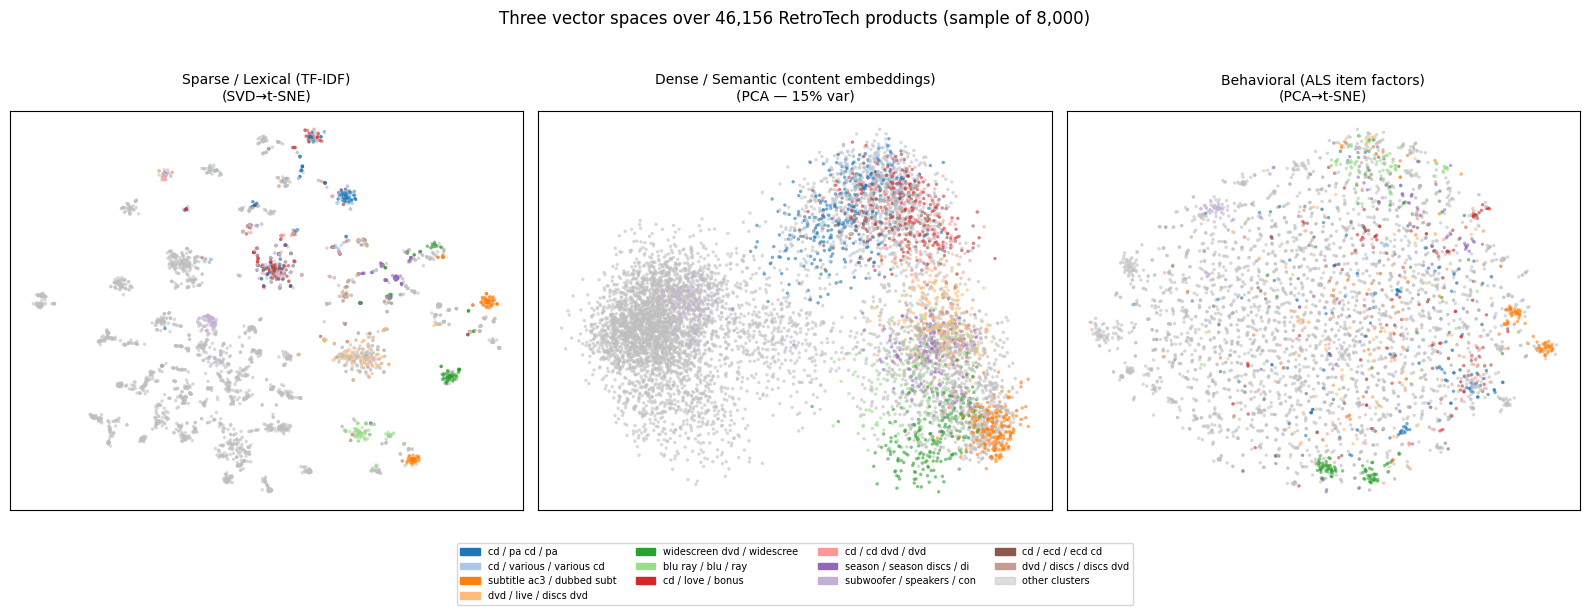

In [17]:
# ── Cell 16: 2-D projections ────────────────────────────────────────────────
top_cats = df["category"].value_counts().head(12).index.tolist()
palette = plt.cm.tab20(np.linspace(0, 1, 20))
CAT_COLORS = {c: palette[i % 20] for i, c in enumerate(top_cats)}
OTHER_COLOR = (0.75, 0.75, 0.75, 0.5)
cat_color = lambda c: CAT_COLORS.get(c, OTHER_COLOR)
rng = np.random.default_rng(RANDOM_SEED)
plot_idx = rng.choice(len(df), size=min(PLOT_SAMPLE, len(df)), replace=False)
plot_colors = [cat_color(c) for c in df["category"].iloc[plot_idx]]

def project_linear(matrix):
    M = normalize(matrix, norm="l2")
    model = TruncatedSVD(2, random_state=RANDOM_SEED) if sp.issparse(matrix) else PCA(2, random_state=RANDOM_SEED)
    return model.fit_transform(M), float(model.explained_variance_ratio_.sum())

def project_tsne(matrix):
    from sklearn.manifold import TSNE
    n = min(TSNE_SAMPLE, len(df))
    idx = np.random.default_rng(RANDOM_SEED).choice(len(df), size=n, replace=False)
    sub = matrix[idx]
    pre = min(TSNE_PRE_DIMS, min(sub.shape) - 1)
    sub = (TruncatedSVD(pre, random_state=RANDOM_SEED).fit_transform(sub) if sp.issparse(sub)
           else PCA(pre, random_state=RANDOM_SEED).fit_transform(sub) if sub.shape[1] > pre else sub)
    emb = TSNE(n_components=2, random_state=RANDOM_SEED, init="pca", perplexity=30,
               metric="cosine").fit_transform(normalize(sub))
    out = np.full((len(df), 2), np.nan); out[idx] = emb
    return out

t0 = time.time()
MATRICES = {"sparse": sparse_matrix, "dense": dense_matrix, "behavioral": V_latent}
PROJ, EV = {}, {}
for s, M in MATRICES.items(): PROJ[s], EV[s] = project_linear(M)
PROJ["sparse_tsne"] = project_tsne(sparse_matrix)
PROJ["behavioral_tsne"] = project_tsne(V_latent)
print(f"Projections done in {time.time()-t0:.0f}s")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
panels = [("sparse_tsne", "Sparse / Lexical (TF-IDF)\n(SVD→t-SNE)"),
          ("dense", f"Dense / Semantic (content embeddings)\n(PCA — {EV['dense']*100:.0f}% var)"),
          ("behavioral_tsne", "Behavioral (ALS item factors)\n(PCA→t-SNE)")]
for ax, (key, title) in zip(axes, panels):
    proj = PROJ[key]; ok = ~np.isnan(proj[plot_idx, 0])
    ax.scatter(proj[plot_idx][ok, 0], proj[plot_idx][ok, 1],
               c=[plot_colors[j] for j in np.where(ok)[0]], s=6, alpha=0.6, linewidths=0, rasterized=True)
    ax.set_title(title, fontsize=10, pad=8); ax.set_xticks([]); ax.set_yticks([])
patches = [mpatches.Patch(color=CAT_COLORS[c], label=c[:26]) for c in top_cats]
patches.append(mpatches.Patch(color=OTHER_COLOR, label="other clusters"))
fig.legend(handles=patches, loc="lower center", ncol=4, fontsize=7, framealpha=0.8, bbox_to_anchor=(0.5, -0.17))
plt.suptitle(f"Three vector spaces over {len(df):,} RetroTech products (sample of {len(plot_idx):,})", fontsize=12, y=1.03)
plt.tight_layout(); plt.savefig("retrotech_spaces_2d.png", dpi=140, bbox_inches="tight"); plt.show()

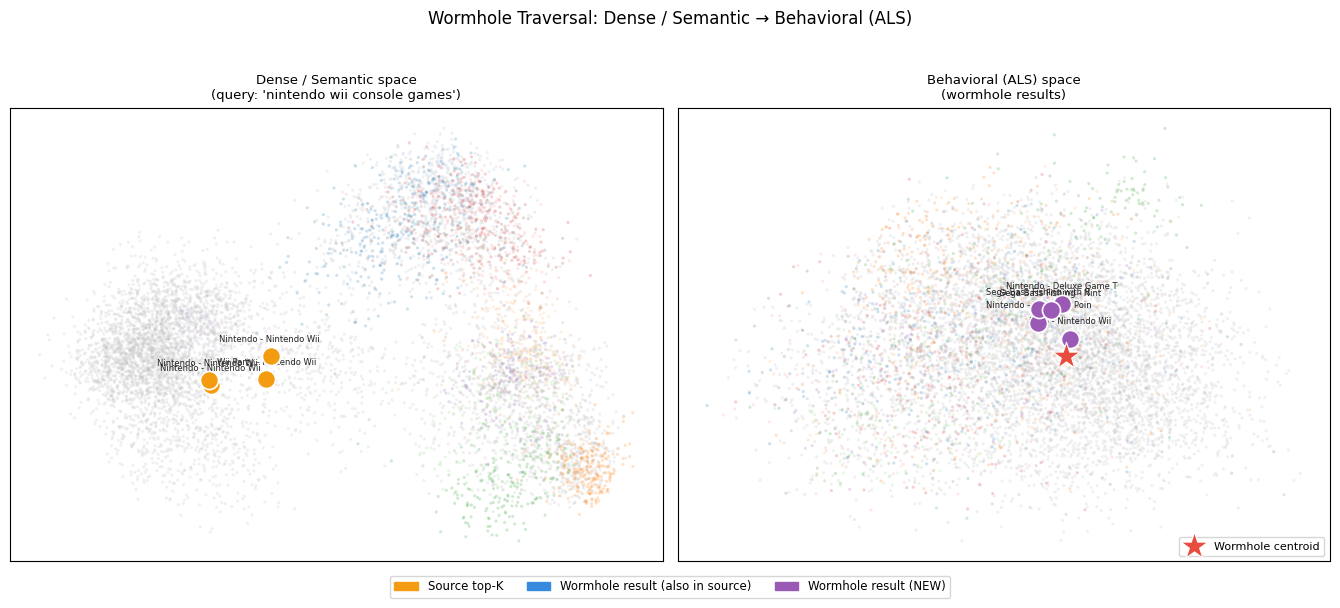

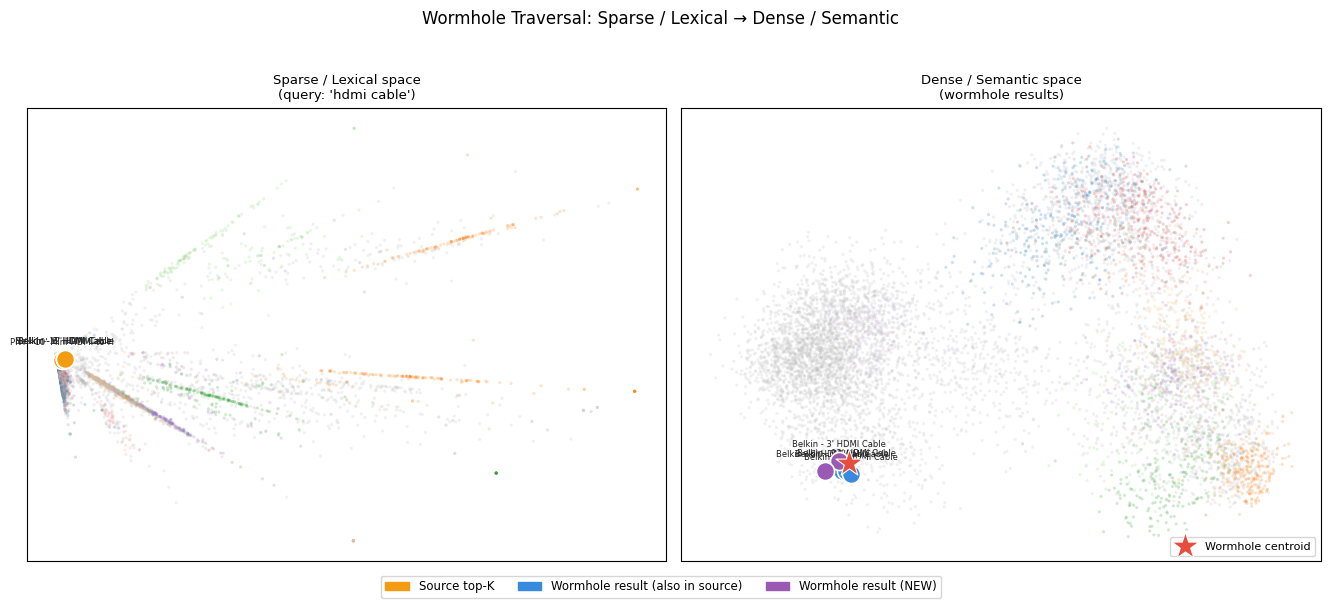

In [18]:
# ── Cell 17: A single traversal, drawn ──────────────────────────────────────
def plot_wormhole(query, source_space="dense", target_space="behavioral", top_k=TOP_K):
    src, wormhole, tgt = wormhole_traverse(query, source_space, target_space, top_k=top_k, verbose=False)
    src_ids = {h["_id"] for h in src}; new_ids = {h["_id"] for h in tgt} - src_ids
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
    for ax, space, results in [(axes[0], source_space, src), (axes[1], target_space, tgt)]:
        proj = PROJ[space]                        # linear projection: every doc has coordinates
        ax.scatter(proj[plot_idx, 0], proj[plot_idx, 1], c=plot_colors, s=5, alpha=0.22, linewidths=0, rasterized=True, zorder=2)
        for h in results:
            i = row_of_upc.get(h["_id"])
            if i is None: continue
            is_new = space == target_space and h["_id"] in new_ids
            color = "#9B59B6" if is_new else ("#F39C12" if space == source_space else "#378add")
            ax.scatter(proj[i, 0], proj[i, 1], c=color, s=170, zorder=4, edgecolors="white", linewidths=1.2)
            ax.annotate(h["name"][:24], (proj[i, 0], proj[i, 1]), fontsize=6, ha="center", va="bottom",
                        xytext=(0, 9), textcoords="offset points", color="#222")
        if space == target_space:
            ids = [row_of_upc[i] for i in src_ids if i in row_of_upc]
            ax.scatter(proj[ids, 0].mean(), proj[ids, 1].mean(), marker="*", s=420, c="#E74C3C",
                       zorder=5, edgecolors="white", linewidths=0.8, label="Wormhole centroid")
            ax.legend(fontsize=8, loc="lower right")
        ax.set_title(f"{SPACE_LABELS[space]} space\n({'query: ' + repr(query) if space == source_space else 'wormhole results'})", fontsize=9.5, pad=6)
        ax.set_xticks([]); ax.set_yticks([])
    fig.legend(handles=[mpatches.Patch(color="#F39C12", label="Source top-K"),
                        mpatches.Patch(color="#378add", label="Wormhole result (also in source)"),
                        mpatches.Patch(color="#9B59B6", label="Wormhole result (NEW)")],
               loc="lower center", ncol=3, fontsize=8.5, framealpha=0.8, bbox_to_anchor=(0.5, -0.05))
    plt.suptitle(f"Wormhole Traversal: {SPACE_LABELS[source_space]} → {SPACE_LABELS[target_space]}", fontsize=12, y=1.03)
    plt.tight_layout(); plt.savefig(f"wormhole_{source_space}_to_{target_space}.png", dpi=140, bbox_inches="tight"); plt.show()
    return src, wormhole, tgt

_ = plot_wormhole("nintendo wii console games", "dense", "behavioral")
_ = plot_wormhole("hdmi cable", "sparse", "dense")

## 9  Personalized wormholes from the user-feature matrix

ALS user factors live in the same latent space as the item factors, so a user's taste vector is itself a behavioral query — served by the same `knn` field:

> **user latent vector** → `knn` on `behavioral_embedding` → pool those products' `content_embedding` → semantically similar products the user has never touched

In [19]:
# ── Cell 18: Personalized wormhole ──────────────────────────────────────────
user_counts = prefs_pd.groupby("user").size().sort_values(ascending=False)
demo_user = user_counts.index[3]
bought = [row_of_upc[u] for u in prefs_pd.loc[prefs_pd["user"] == demo_user, "product"] if u in row_of_upc]
print(f"Demo user {demo_user}: {user_counts.iloc[3]} interactions, e.g.")
for i in bought[:6]: print(f"   • [{df['category'].iloc[i][:26]}] {df['name'].iloc[i][:55]}")

def personalized_wormhole(user_id, target_space="dense", wormhole_k=WORMHOLE_K, top_k=TOP_K):
    uvec = user_F[user_index[user_id]]; uvec = uvec / (np.linalg.norm(uvec) + 1e-12)
    src = vector_search("behavioral", uvec, wormhole_k)
    print(f"\n── Step 1: BEHAVIORAL knn for the user's latent vector"); show(src)
    wormhole = skg_wormhole_terms(src) if target_space == "sparse" else pooled_wormhole_vector(src, target_space)
    if target_space == "sparse": print(f"\n── the words that describe this user's taste:\n   {fmt_terms(wormhole)}")
    tgt = search_with_wormhole(target_space, wormhole, top_k)
    print(f"\n── Step 2-4: {SPACE_LABELS[target_space]} results via the personalized wormhole")
    show(tgt, source_ids={h["_id"] for h in src})
    return src, wormhole, tgt

_ = personalized_wormhole(demo_user, "dense")
_ = personalized_wormhole(demo_user, "sparse")

Demo user u186672: 12 interactions, e.g.
   • [megapixel / megapixel digi] Nikon - D7000 16.2-Megapixel DSLR Camera (Body Only) - 
   • [memory card / memory / fla] Hello Kitty - 4GB USB Flash Drive
   • [apple ipod / ipod / apple] Sony - Clock Radio with Apple® iPhone® and iPod® Dock
   • [lenmar / lenmar lithium / ] Lenmar - Lithium-Ion Battery for HTC HD7 Windows 7 phon
   • [ch / home theater / theate] Philips - 2.1-Ch. Home Theater Soundbar Speaker System 
   • [mobile phone / mobile / ph] Google - Nexus S Mobile Phone - Black (Sprint)

── Step 1: BEHAVIORAL knn for the user's latent vector
   [0.9368] [microphone / behringer / a] Alesis - PerformancePad Electronic Drum Machine
   [0.8568] [microphone / behringer / a] Alesis - DMPad 1-Piece Drum Pad
   [0.8501] [guitar / string size / str] Alesis - Surge 12" Hi-Hat Cymbal - Gold
   [0.8464] [microphone / behringer / a] Sabian - 10" AAX Splash Cymbal

── Step 2-4: Dense / Semantic results via the personalized wormhole
   [0.9418] [

## 10  Agentic search with wormhole tools

Most agentic search gives the model two unrelated tools — `keyword_search` and `vector_search` — and lets it reconcile the two result lists in its context window. A wormhole traversal is a better tool: one call moves between spaces *inside the engine*, and its intermediate products (the SKG terms, the behavioral neighbours) are explanations the agent can reason over.

Below, Claude gets five tools over the backend and is asked a question that needs all three spaces. Watch the trace: `explain_query` (a dense→sparse wormhole) is how the agent finds out what the catalog thinks a query means before it commits to a retrieval.

OpenSearch 3.x ships native agentic search (the `agentic` query type backed by ML Commons agents and a `QueryPlanningTool`); the same tool definitions plug into that as `ListIndexTool`/`SearchIndexTool`-style tools. Here the loop is in Python so it runs against 2.x as well.

In [20]:
# ── Cell 19: Tools for an agent ─────────────────────────────────────────────
def _brief(hits):
    return [{"upc": h["_id"], "name": h["name"], "cluster": h.get("cluster_label", ""),
             "score": round(float(h["score"]), 4)} for h in hits]

def tool_lexical_search(query, k=TOP_K):
    return _brief(lexical_search(query, k))

def tool_semantic_search(query, k=TOP_K):
    return _brief(dense_search(query, k))

def tool_explain_query(query, k=8):
    """dense→sparse wormhole, two levels: the SENSES of this query — each candidate
    category, with the terms that belong to it."""
    hits = dense_search(query, SKG_K)
    return {"senses": [{"category": s["category"], "share": s["share"],
                        "terms": {t["term"]: t["score"] for t in s["terms"]}}
                       for s in skg_wormhole_senses(hits)],
            "all_terms": [{"term": t["term"], "score": round(t["score"], 3)}
                          for t in skg_wormhole_terms(hits, size=k)]}

def tool_bought_together(query, source_space="dense", k=TOP_K):
    """(sparse|dense)→behavioral wormhole: what customers buy in this context."""
    _, _, tgt = wormhole_traverse(query, source_space, "behavioral", top_k=k, verbose=False)
    return _brief(tgt)

def tool_wormhole_hybrid_search(query, k=TOP_K, category=None):
    """`category` (copied from an explain_query sense) constrains every sub-query."""
    return _brief(wormhole_hybrid(query, k, category=category))

AGENT_TOOLS = [
    {"name": "lexical_search", "description": "BM25 keyword search over product name/description in OpenSearch. Best for exact model names and part numbers.",
     "input_schema": {"type": "object", "properties": {"query": {"type": "string"}, "k": {"type": "integer"}}, "required": ["query"]}},
    {"name": "semantic_search", "description": "Dense vector (kNN) search over product content embeddings. Best for descriptive or conceptual queries.",
     "input_schema": {"type": "object", "properties": {"query": {"type": "string"}, "k": {"type": "integer"}}, "required": ["query"]}},
    {"name": "explain_query", "description": "Query understanding via a two-level dense→sparse wormhole: retrieves the query's semantic neighbours, then runs a nested Semantic Knowledge Graph traversal that splits them into candidate SENSES — each a category with the terms that are statistically over-represented inside it. Use this FIRST to learn what the catalog thinks a query means, to disambiguate it, and to get better keywords.",
     "input_schema": {"type": "object", "properties": {"query": {"type": "string"}, "k": {"type": "integer"}}, "required": ["query"]}},
    {"name": "bought_together", "description": "Behavioral wormhole: finds products matching the query, then jumps into the collaborative-filtering space to return what customers who engage with those products also buy. Use for accessories, bundles, 'what goes with X'.",
     "input_schema": {"type": "object", "properties": {"query": {"type": "string"}, "source_space": {"type": "string", "enum": ["sparse", "dense"]}, "k": {"type": "integer"}}, "required": ["query"]}},
    {"name": "wormhole_hybrid_search", "description": "Single OpenSearch hybrid query combining BM25, a wormhole content vector, a wormhole behavioral vector and SKG term expansion. The strongest general-purpose retrieval; use for the final product list. Pass `category` (copied verbatim from an explain_query sense) to constrain the entire query to that sense — do this when explain_query shows the query is ambiguous and you have decided which sense the shopper means.",
     "input_schema": {"type": "object", "properties": {"query": {"type": "string"}, "k": {"type": "integer"}, "category": {"type": "string", "description": "A category string from explain_query's senses, copied verbatim."}}, "required": ["query"]}},
]
TOOL_FNS = {"lexical_search": tool_lexical_search, "semantic_search": tool_semantic_search,
            "explain_query": tool_explain_query, "bought_together": tool_bought_together,
            "wormhole_hybrid_search": tool_wormhole_hybrid_search}

# What the tools hand back to the agent (real output) — the raw material for its reasoning
print('explain_query("wii") →')
out = tool_explain_query("wii")
for s in out["senses"]:
    print(f'   [{s["share"]*100:>3.0f}%] {s["category"][:34]:<36}'
          f'{"  ".join(f"{t}^{w}" for t, w in s["terms"].items())}')
print('\nbought_together("nintendo wii") →')
for r in tool_bought_together("nintendo wii"): print(f"   [{r['score']:.3f}] {r['name'][:64]}")
print('\nwormhole_hybrid_search("nintendo wii") →')
for r in tool_wormhole_hybrid_search("nintendo wii"): print(f"   [{r['score']:.3f}] {r['name'][:64]}")
print('\nwormhole_hybrid_search("monster", category="dvd / movie dvd / discs dvd") →')
for r in tool_wormhole_hybrid_search("monster", category="dvd / movie dvd / discs dvd"):
    print(f"   [{r['score']:.3f}] {r['name'][:64]}")

explain_query("wii") →
   [100%] nintendo / wii / nintendo wii       wii^1.0  nintendo^0.4735  mario^0.394  console^0.3281  success^0.2605  love^0.2025

bought_together("nintendo wii") →
   [0.951] Nintendo - Deluxe Game Traveler Case for Nintendo Wii
   [0.941] Sega Bass Fishing with Rod for Nintendo Wii - Nintendo Wii
   [0.939] Nintendo - Nintendo Points Card for Nintendo Wii ($19.99)
   [0.918] Trivial Pursuit - Nintendo Wii
   [0.917] Sega Bass Fishing - Nintendo Wii

wormhole_hybrid_search("nintendo wii") →
   [0.604] Nintendo Selects: Wii Sports - Nintendo Wii
   [0.537] Wii Party - Nintendo Wii
   [0.350] Nintendo - Wii Wheel for Nintendo Wii
   [0.200] Mario Kart Wii with Wii Wheel - Nintendo Wii
   [0.165] Nintendo - Wii MotionPlus Accessory for Nintendo Wii

wormhole_hybrid_search("monster", category="dvd / movie dvd / discs dvd") →


In [21]:
# ── Cell 20: The agent loop ─────────────────────────────────────────────────
def _api_key():
    key = os.getenv("ANTHROPIC_API_KEY")
    if not key:
        for p in [".anthropic_key", os.path.expanduser("~/.anthropic_key")]:
            if os.path.exists(p): key = open(p).read().strip(); break
    return key

AGENT_MODEL = "claude-opus-5"
SYSTEM = """You are a shopping assistant for RetroTech, an electronics retailer. You answer
by calling the search tools over the store's OpenSearch index. Prefer wormhole tools
(explain_query, bought_together, wormhole_hybrid_search) when a question involves
intent, accessories, or 'what goes with' — they traverse between the lexical, semantic
and behavioral spaces inside the engine. Keep the final answer short: a few products
with one-line reasons, citing UPCs."""

def run_agent(question, max_turns=8, verbose=True):
    key = _api_key()
    if not key:
        print("ANTHROPIC_API_KEY not set — skipping the live agent. "
              "(export it, or put it in ./.anthropic_key)"); return None
    try:
        import anthropic
    except ImportError:
        import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "anthropic"], check=True)
        import anthropic
    # Accept-Encoding: identity works around an old zstandard build in the AIPS image
    # (httpx2's decompressor raises TypeError on compressed responses there).
    client = anthropic.Anthropic(api_key=key, default_headers={"Accept-Encoding": "identity"})
    messages = [{"role": "user", "content": question}]
    if verbose: print(f"USER: {question}\n")
    for turn in range(max_turns):
        resp = client.messages.create(model=AGENT_MODEL, max_tokens=4096, system=SYSTEM,
                                      tools=AGENT_TOOLS, messages=messages,
                                      thinking={"type": "adaptive"},
                                      output_config={"effort": "medium"})
        messages.append({"role": "assistant", "content": resp.content})
        if resp.stop_reason != "tool_use":
            text = "".join(b.text for b in resp.content if b.type == "text")
            if verbose: print(f"\nAGENT: {text}")
            return text
        results = []
        for block in resp.content:
            if block.type == "text" and block.text.strip() and verbose:
                print(f"agent: {block.text.strip()}")
            if block.type != "tool_use": continue
            args = dict(block.input)
            if verbose: print(f"  → {block.name}({json.dumps(args)})")
            try:
                out = TOOL_FNS[block.name](**args)
                if verbose:
                    if isinstance(out, list):
                        for r in out[:5]: print(f"      [{r['score']:.3f}] {r['name'][:60]}")
                    else: print("      " + json.dumps(out)[:300])
                results.append({"type": "tool_result", "tool_use_id": block.id, "content": json.dumps(out)})
            except Exception as e:
                results.append({"type": "tool_result", "tool_use_id": block.id, "content": f"error: {e}", "is_error": True})
        messages.append({"role": "user", "content": results})
    return None

_ = run_agent("I'm buying a Nintendo Wii for my kids. What else should I pick up so it's ready to play on my TV?")

ANTHROPIC_API_KEY not set — skipping the live agent. (export it, or put it in ./.anthropic_key)


In [22]:
# ── Cell 21: A second question that needs the sparse wormhole ───────────────
_ = run_agent("Someone searched our store for 'ipod'. What are they most likely looking for, "
              "and what are the best three products to show them?")

ANTHROPIC_API_KEY not set — skipping the live agent. (export it, or put it in ./.anthropic_key)


### The one that needs the two-level traversal

`monster` is three different products in this catalog. A flat query-understanding step has to pick one; the two-level traversal hands the agent all three senses with their term vectors, and `wormhole_hybrid_search(category=...)` lets it commit to one **inside the engine** instead of guessing at a query rewrite.

In [23]:
# ── Cell 21b: an ambiguous query the agent has to disambiguate ──────────────
_ = run_agent("A customer typed 'monster' into our search box. Figure out what they could "
              "mean, then show me the best three products for each distinct meaning.")


ANTHROPIC_API_KEY not set — skipping the live agent. (export it, or put it in ./.anthropic_key)


## 11  Interactive explorer

In [26]:
# ── Cell 22: Widget ─────────────────────────────────────────────────────────
import ipywidgets as widgets
from IPython.display import display, clear_output

query_input = widgets.Text(value="hdmi cable", description="Query:", layout=widgets.Layout(width="55%"), style={"description_width": "60px"})
source_dd = widgets.Dropdown(options=["sparse", "dense"], value="sparse", description="From:", layout=widgets.Layout(width="170px"), style={"description_width": "40px"})
target_dd = widgets.Dropdown(options=["behavioral", "dense", "sparse"], value="behavioral", description="To:", layout=widgets.Layout(width="190px"), style={"description_width": "35px"})
run_btn = widgets.Button(description="Generate Wormhole →", button_style="primary", layout=widgets.Layout(width="190px"))
out = widgets.Output()

def on_run(b):
    with out:
        clear_output(wait=True)
        if target_dd.value == "sparse":
            wormhole_traverse(query_input.value, source_dd.value, "sparse")
        else:
            src, _, tgt = plot_wormhole(query_input.value, source_dd.value, target_dd.value)
            print("\n── Source:"); show(src); print("\n── Target (wormhole):"); show(tgt, source_ids={h["_id"] for h in src})
run_btn.on_click(on_run)
display(widgets.VBox([widgets.HTML("<b>Wormhole Vector Explorer — RetroTech on OpenSearch</b>"),
                      widgets.HBox([query_input]), widgets.HBox([source_dd, target_dd]), run_btn, out]))

---

## Summary

| Concept | OpenSearch implementation |
|---|---|
| One index, three spaces | `products_wormhole`: text fields + `content_embedding` (384-d) + `behavioral_embedding` (32-d) as `knn_vector` |
| Sparse / lexical search | `multi_match` (BM25) over the inverted index |
| Dense & behavioral search | `knn` queries (HNSW, cosine) |
| Wormhole **into** dense / behavioral | `_mget` the top-K docs' vectors → score-weighted pooling → `knn` |
| Wormhole **into** sparse (SKG) | `significant_text` aggregation over the top-K docs → boosted `bool.should` |
| Hybrid across all of them | native `hybrid` query + `normalization-processor` (min-max, weighted mean); RRF via `score-ranker-processor` on 2.19+ |
| Cold start | behavioral vectors imputed through a content→behavioral wormhole |
| Agentic search | wormhole traversals exposed as tools (`explain_query`, `bought_together`, `wormhole_hybrid_search`) 

**Key takeaway:** hybrid fusion combines two rankings that never talk to each other. A wormhole vector lets one space *inform* the query in another — and OpenSearch already has every primitive it needs: kNN fields, `_mget`, `significant_text`, and the `hybrid` query.